In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier

RANDOM_SEED = 42
feature_cols = [f"f{i}" for i in range(63)]

train_df = pd.read_csv("../data/processed/train.csv")
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df["label"].astype(str).to_numpy()

print("Train loaded:", X_train.shape)

Train loaded: (2165, 63)


In [2]:
final_models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=3))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=100, gamma=0.01, probability=True))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=20, random_state=RANDOM_SEED))
    ]),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(100, 50), learning_rate_init=0.001, max_iter=1000, random_state=RANDOM_SEED))
    ]),
}

for name, model in final_models.items():
    model.fit(X_train, y_train)
    print(f"{name}: trained on full training set ({len(X_train)} samples)")

Baseline: trained on full training set (2165 samples)
KNN: trained on full training set (2165 samples)


D:\CS 5 Course\ML(Lab)\Project\psl-translator\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF): trained on full training set (2165 samples)


Random Forest: trained on full training set (2165 samples)


MLP: trained on full training set (2165 samples)


In [3]:
# WE OPEN THE TEST SET FOR THE FIRST TIME HERE
test_df = pd.read_csv("../data/processed/test.csv")
X_test = test_df[feature_cols].to_numpy(dtype=np.float64)
y_test = test_df["label"].astype(str).to_numpy()

print("Test set loaded:", X_test.shape)
print("Test classes:", len(np.unique(y_test)))

test_predictions = {}
for name, model in final_models.items():
    preds = model.predict(X_test)
    test_predictions[name] = preds
    accuracy = (preds == y_test).mean()
    print(f"{name}: test accuracy = {accuracy:.4f}")

Test set loaded: (562, 63)
Test classes: 36
Baseline: test accuracy = 0.0285


KNN: test accuracy = 0.8826


SVM (RBF): test accuracy = 0.9502
Random Forest: test accuracy = 0.9146
MLP: test accuracy = 0.9377


In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

metrics_table = []

for name, preds in test_predictions.items():
    metrics_table.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision (macro)": precision_score(y_test, preds, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, preds, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, preds, average="macro", zero_division=0),
    })

metrics_df = pd.DataFrame(metrics_table).round(4)
metrics_df = metrics_df.sort_values("F1 (macro)", ascending=False)
metrics_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
2,SVM (RBF),0.9502,0.9524,0.9485,0.9482
4,MLP,0.9377,0.9396,0.9358,0.9361
3,Random Forest,0.9146,0.9165,0.9128,0.9129
1,KNN,0.8826,0.8859,0.8811,0.8810
0,Baseline,0.0285,0.0008,0.0278,0.0015


In [5]:
metrics_df.to_csv("../results/final_results.csv", index=False)
print("Saved:", metrics_df.shape)
metrics_df

Saved: (5, 5)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
2,SVM (RBF),0.9502,0.9524,0.9485,0.9482
4,MLP,0.9377,0.9396,0.9358,0.9361
3,Random Forest,0.9146,0.9165,0.9128,0.9129
1,KNN,0.8826,0.8859,0.8811,0.8810
0,Baseline,0.0285,0.0008,0.0278,0.0015


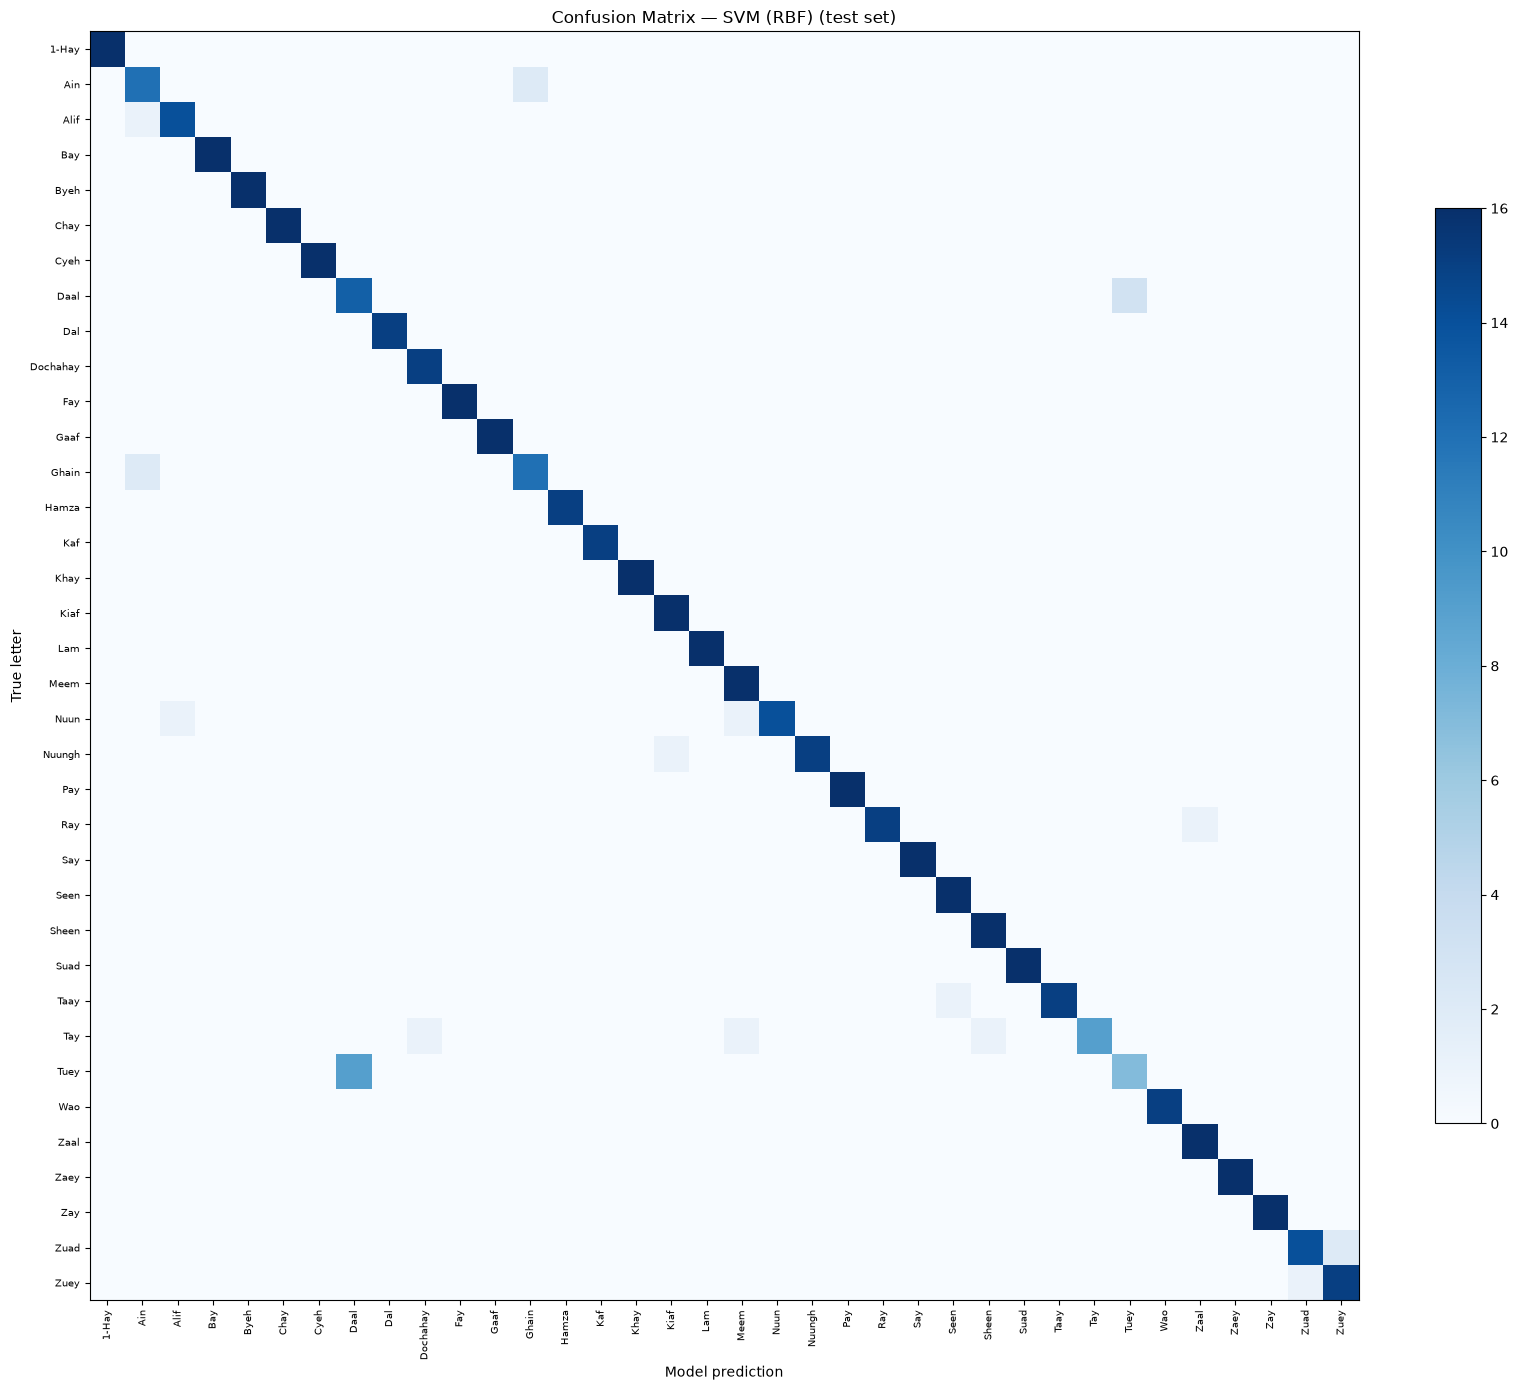

In [6]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

best_model_name = "SVM (RBF)"
best_preds = test_predictions[best_model_name]

labels_sorted = sorted(np.unique(y_test))
cm = confusion_matrix(y_test, best_preds, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(len(labels_sorted)))
ax.set_yticks(range(len(labels_sorted)))
ax.set_xticklabels(labels_sorted, rotation=90, fontsize=7)
ax.set_yticklabels(labels_sorted, fontsize=7)
ax.set_xlabel("Model prediction")
ax.set_ylabel("True letter")
ax.set_title(f"Confusion Matrix — {best_model_name} (test set)")

plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.savefig("../reports/figures/05_confusion_matrix.png", dpi=150)
plt.show()

# also save it as a CSV, it will be used for the analysis in Steps 85-86
cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
cm_df.to_csv("../results/confusion_matrix.csv")

In [7]:
confusions = []

for i, true_label in enumerate(labels_sorted):
    for j, pred_label in enumerate(labels_sorted):
        if i != j and cm[i, j] > 0:  # skip the diagonal, only where a mistake happened
            confusions.append({
                "True letter": true_label,
                "Predicted letter": pred_label,
                "Count": cm[i, j]
            })

confusions_df = pd.DataFrame(confusions).sort_values("Count", ascending=False)

print("Top 5 most confused pairs:")
confusions_df.head(5)

Top 5 most confused pairs:


,True letter,Predicted letter,Count
12,Tuey,Daal,9
2,Daal,Tuey,3
0,Ain,Ghain,2
13,Zuad,Zuey,2
3,Ghain,Ain,2


In [8]:
from sklearn.metrics import classification_report

report_dict = classification_report(y_test, best_preds, output_dict=True, zero_division=0)

per_class_df = pd.DataFrame(report_dict).T  # .T = swap rows/columns, so the letters become rows
per_class_df = per_class_df.drop(["accuracy", "macro avg", "weighted avg"], errors="ignore")
per_class_df = per_class_df.sort_values("f1-score")

print("Weakest 5 letters (lowest F1):")
per_class_df.head(5)

Weakest 5 letters (lowest F1):


,precision,recall,f1-score,support
Tuey,0.700000,0.437500,0.538462,16.0
Daal,0.590909,0.812500,0.684211,16.0
Ain,0.800000,0.857143,0.827586,14.0
Ghain,0.857143,0.857143,0.857143,14.0
Tay,1.000000,0.750000,0.857143,12.0


In [9]:
per_class_df.to_csv("../results/per_class_report.csv")
print("Saved per-class report:", per_class_df.shape)

Saved per-class report: (36, 4)


In [10]:
import joblib

best_model = final_models["SVM (RBF)"]

joblib.dump(best_model, "../models/best_model.joblib")

print("Model saved!")
print("File size:", round(Path("../models/best_model.joblib").stat().st_size / 1024, 1), "KB")

Model saved!
File size: 1284.6 KB


In [11]:
class_names = sorted(train_df["label"].unique().tolist())

joblib.dump(class_names, "../models/class_names.joblib")

print("Total classes:", len(class_names))
print(class_names)

Total classes: 36
['1-Hay', 'Ain', 'Alif', 'Bay', 'Byeh', 'Chay', 'Cyeh', 'Daal', 'Dal', 'Dochahay', 'Fay', 'Gaaf', 'Ghain', 'Hamza', 'Kaf', 'Khay', 'Kiaf', 'Lam', 'Meem', 'Nuun', 'Nuungh', 'Pay', 'Ray', 'Say', 'Seen', 'Sheen', 'Suad', 'Taay', 'Tay', 'Tuey', 'Wao', 'Zaal', 'Zaey', 'Zay', 'Zuad', 'Zuey']
